In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBClassifier
from scipy.stats import randint, uniform

RANDOM_STATE = 42

In [104]:
columns = [
    'loan_amnt', 'term', 'int_rate', 'installment',
    'grade', 'emp_length', 'home_ownership',
    'annual_inc', 'verification_status',
    'loan_status', 'purpose', 'dti',
    'open_acc', 'revol_util', 'total_acc', 'mort_acc'
]

df = pd.read_csv(
    "Data/lending_club_loan_two.csv",
    usecols=columns,
    nrows=50000,
    low_memory=False
)

df = df[df['loan_status'].isin(
    ['Fully Paid', 'Charged Off']
)].copy()

df = df.sample(
    n=min(25000, len(df)),
    random_state=42
)

df['loan_status'] = df['loan_status'].map({
    'Fully Paid': 0,
    'Charged Off': 1
})

print("Dataset Shape:", df.shape)
print("\nLoan Status Distribution:")
print(df['loan_status'].value_counts())

Dataset Shape: (25000, 16)

Loan Status Distribution:
loan_status
0    20111
1     4889
Name: count, dtype: int64


In [105]:
X = df.drop(columns=['loan_status', 'installment'])
y = df['loan_status']

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

Training Data: (15000, 14)
Validation Data: (5000, 14)
Testing Data: (5000, 14)


In [106]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Columns:", numeric_features)
print("\nCategorical Columns:", categorical_features)

Numerical Columns: ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'open_acc', 'revol_util', 'total_acc', 'mort_acc']

Categorical Columns: ['term', 'grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose']


In [107]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_features),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

In [108]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'XGBoost': XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        eval_metric='logloss',
        random_state=42,
        n_jobs=1
    )
}

In [109]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully")

Logistic Regression trained successfully
Random Forest trained successfully
XGBoost trained successfully


In [110]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))
])

rf_params = {
    'model__n_estimators': [100, 150],
    'model__max_depth': [8, 12],
    'model__min_samples_split': [2, 5]
}

In [111]:
grid_search = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best ROC-AUC Score:", round(grid_search.best_score_, 4))

trained_models['Random Forest'] = grid_search.best_estimator_

Best Parameters: {'model__max_depth': 8, 'model__min_samples_split': 2, 'model__n_estimators': 150}
Best ROC-AUC Score: 0.7061


In [112]:
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        eval_metric='logloss',
        random_state=42,
        n_jobs=1
    ))
])

xgb_params = {
    'model__n_estimators': [100, 150, 200],
    'model__max_depth': [3, 4, 5, 6],
    'model__learning_rate': [0.03, 0.05, 0.1, 0.15]
}

In [113]:
random_search = RandomizedSearchCV(
    xgb_pipeline,
    xgb_params,
    n_iter=15,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best ROC-AUC Score:", round(random_search.best_score_, 4))

trained_models['XGBoost'] = random_search.best_estimator_

Best Parameters: {'model__n_estimators': 100, 'model__max_depth': 3, 'model__learning_rate': 0.05}
Best ROC-AUC Score: 0.7071


In [114]:
validation_scores = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)
    auc = roc_auc_score(y_val, y_prob)

    validation_scores[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'ROC-AUC': auc
    }

    print(f"\n{name}")
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("ROC-AUC  :", round(auc, 4))
    print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred))


Logistic Regression
Accuracy : 0.6398
Precision: 0.3026
Recall   : 0.6452
F1 Score : 0.412
ROC-AUC  : 0.6853
Confusion Matrix:
 [[2568 1454]
 [ 347  631]]

Random Forest
Accuracy : 0.6486
Precision: 0.305
Recall   : 0.6227
F1 Score : 0.4094
ROC-AUC  : 0.6876
Confusion Matrix:
 [[2634 1388]
 [ 369  609]]

XGBoost
Accuracy : 0.6496
Precision: 0.3067
Recall   : 0.6278
F1 Score : 0.4121
ROC-AUC  : 0.6909
Confusion Matrix:
 [[2634 1388]
 [ 364  614]]


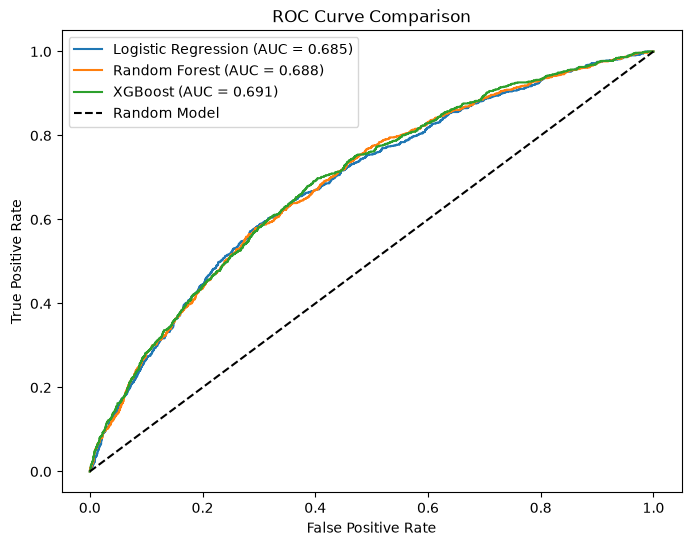

In [115]:
plt.figure(figsize=(8, 6))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_val)[:, 1]

    fpr, tpr, _ = roc_curve(y_val, y_prob)
    auc = roc_auc_score(y_val, y_prob)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Model')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

In [116]:
best_model_name = max(
    validation_scores,
    key=lambda name: validation_scores[name]['ROC-AUC']
)

best_model = trained_models[best_model_name]

y_prob = best_model.predict_proba(X_val)[:, 1]

precision_values, recall_values, thresholds = precision_recall_curve(
    y_val, y_prob
)

valid_indices = np.where(recall_values[:-1] >= 0.75)[0]

best_index = valid_indices[
    np.argmax(precision_values[:-1][valid_indices])
]

best_threshold = thresholds[best_index]

print("Best Model:", best_model_name)
print("Selected Threshold:", round(best_threshold, 4))
print("Recall:", round(recall_values[best_index], 4))
print("Precision:", round(precision_values[best_index], 4))

Best Model: XGBoost
Selected Threshold: 0.4305
Recall: 0.7505
Precision: 0.2795


In [117]:
reg_features = [
    'term', 'int_rate', 'grade', 'emp_length',
    'home_ownership', 'annual_inc',
    'verification_status', 'purpose',
    'dti', 'open_acc', 'revol_util',
    'total_acc', 'mort_acc'
]

X_reg = df[reg_features]
y_reg = df['loan_amnt']

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

reg_num = X_reg.select_dtypes(include=np.number).columns.tolist()
reg_cat = X_reg.select_dtypes(exclude=np.number).columns.tolist()

In [118]:
reg_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), reg_num),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), reg_cat)
])

In [119]:
reg_model = Pipeline([
    ('preprocessor', reg_preprocessor),

    ('model', RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ))
])

reg_model.fit(X_reg_train, y_reg_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['term','int_rate','grade',...,'revol_util','total_acc','mort_acc']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis c

In [120]:
baseline = DummyRegressor(strategy='mean')

baseline.fit(X_reg_train, y_reg_train)

reg_pred = reg_model.predict(X_reg_test)
baseline_pred = baseline.predict(X_reg_test)

In [121]:
print("Random Forest Regression")

print("MAE:", round(mean_absolute_error(y_reg_test, reg_pred), 2))

print("RMSE:", round(np.sqrt(mean_squared_error(y_reg_test, reg_pred)), 2))

print("R2:", round(r2_score(y_reg_test, reg_pred), 4))


print("\nMean Baseline")

print("MAE:", round(mean_absolute_error(y_reg_test, baseline_pred), 2))

print("RMSE:", round(np.sqrt(mean_squared_error(y_reg_test, baseline_pred)), 2))

print("R2:", round(r2_score(y_reg_test, baseline_pred), 4))

Random Forest Regression
MAE: 4824.03
RMSE: 6155.54
R2: 0.4642

Mean Baseline
MAE: 6809.0
RMSE: 8410.4
R2: -0.0002


In [122]:
y_test_prob = best_model.predict_proba(X_test)[:, 1]

y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("Best Model:", best_model_name)

print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))

print("Precision:", round(precision_score(y_test, y_test_pred), 4))

print("Recall:", round(recall_score(y_test, y_test_pred), 4))

print("F1 Score:", round(f1_score(y_test, y_test_pred), 4))

print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Best Model: XGBoost
Accuracy: 0.5688
Precision: 0.2772
Recall: 0.7495
F1 Score: 0.4047
ROC-AUC: 0.7051

Confusion Matrix:
[[2111 1911]
 [ 245  733]]


In [123]:
print("XGBoost Validation F1:",
      round(validation_scores['XGBoost']['F1'], 4))

XGBoost Validation F1: 0.4121
